# Volve Oil Production Forecasting

Compare ARIMA, XGBoost, and LSTM forecasts for well `15/9-F-12`.

**Target:** `BORE_OIL_VOL` · **Input:** Volve workbook · **Evaluation:** chronological splits

## Notebook Guide

Run cells top to bottom. Set the workbook path in the input cell.

## Setup and Data

### Imports and Input Path

Import libraries and set the workbook path. The following cells load, filter, and split the production data.

In [5]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import seaborn as sns
import optuna 
import random
from pathlib import Path


from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler, MinMaxScaler


from sklearn.model_selection import (
    train_test_split,
    
    cross_val_score,
)


from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)


from xgboost import XGBRegressor
from keras.models import Sequential
from keras.layers import LSTM
from keras.layers import Dense


import statsmodels.api as sm
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

import tensorflow as tf




In [6]:
FIGURES_DIR = Path.cwd().parent / "figures"
model_DIR = Path.cwd().parent / "models"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
model_DIR.mkdir(parents=True, exist_ok=True)

In [7]:
SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

# Request deterministic TensorFlow operations
tf.config.experimental.enable_op_determinism()

### Load and Select Production Data

Load workbook sheets, select production-only records for `15/9-F-12`, and split chronologically (85/15).

In [8]:
workbook_path=(r"D:\DataSets\Production_data\Volve production data.xlsx")

workbook_sheets = pd.read_excel(workbook_path, sheet_name=None)
daily_production_data = workbook_sheets["Daily Production Data"]
monthly_production_data = workbook_sheets["Monthly Production Data"]

In [9]:
production_only_well_names = (                                    
    daily_production_data.groupby("NPD_WELL_BORE_NAME")["FLOW_KIND"]
    .agg(set)
    .loc[lambda x: x == {"production"}]
)

production_only_well_names

NPD_WELL_BORE_NAME
15/9-F-1 C     {production}
15/9-F-11      {production}
15/9-F-12      {production}
15/9-F-14      {production}
15/9-F-15 D    {production}
Name: FLOW_KIND, dtype: object

In [10]:
production_records = daily_production_data[daily_production_data["NPD_WELL_BORE_NAME"].isin(production_only_well_names.index.tolist())]
target_well_data= production_records[production_records["NPD_WELL_BORE_NAME"] == "15/9-F-12"]


train_test_split_index = int(len(target_well_data) * 0.85)
train_df = target_well_data.iloc[:train_test_split_index].copy()
test_df = target_well_data.iloc[train_test_split_index:].copy()

In [11]:
train_df.set_index("DATEPRD", inplace=True)
test_df.set_index("DATEPRD", inplace=True)

In [12]:
test_df.index

DatetimeIndex(['2015-06-17', '2015-06-18', '2015-06-19', '2015-06-20',
               '2015-06-21', '2015-06-22', '2015-06-23', '2015-06-24',
               '2015-06-25', '2015-06-26',
               ...
               '2016-09-08', '2016-09-09', '2016-09-10', '2016-09-11',
               '2016-09-12', '2016-09-13', '2016-09-14', '2016-09-15',
               '2016-09-16', '2016-09-17'],
              dtype='datetime64[ns]', name='DATEPRD', length=459, freq=None)

## Exploratory Data Analysis

Inspect the selected well's coverage, missing values, and production measures.

### Question and Target

Forecast daily bore oil volume from its history.

In [13]:
train_df.columns

Index(['WELL_BORE_CODE', 'NPD_WELL_BORE_CODE', 'NPD_WELL_BORE_NAME',
       'NPD_FIELD_CODE', 'NPD_FIELD_NAME', 'NPD_FACILITY_CODE',
       'NPD_FACILITY_NAME', 'ON_STREAM_HRS', 'AVG_DOWNHOLE_PRESSURE',
       'AVG_DOWNHOLE_TEMPERATURE', 'AVG_DP_TUBING', 'AVG_ANNULUS_PRESS',
       'AVG_CHOKE_SIZE_P', 'AVG_CHOKE_UOM', 'AVG_WHP_P', 'AVG_WHT_P',
       'DP_CHOKE_SIZE', 'BORE_OIL_VOL', 'BORE_GAS_VOL', 'BORE_WAT_VOL',
       'BORE_WI_VOL', 'FLOW_KIND', 'WELL_TYPE'],
      dtype='object')

In [14]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2597 entries, 2008-02-12 to 2015-06-16
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   WELL_BORE_CODE            2597 non-null   object 
 1   NPD_WELL_BORE_CODE        2597 non-null   int64  
 2   NPD_WELL_BORE_NAME        2597 non-null   object 
 3   NPD_FIELD_CODE            2597 non-null   int64  
 4   NPD_FIELD_NAME            2597 non-null   object 
 5   NPD_FACILITY_CODE         2597 non-null   int64  
 6   NPD_FACILITY_NAME         2597 non-null   object 
 7   ON_STREAM_HRS             2597 non-null   float64
 8   AVG_DOWNHOLE_PRESSURE     2591 non-null   float64
 9   AVG_DOWNHOLE_TEMPERATURE  2591 non-null   float64
 10  AVG_DP_TUBING             2591 non-null   float64
 11  AVG_ANNULUS_PRESS         2584 non-null   float64
 12  AVG_CHOKE_SIZE_P          2553 non-null   float64
 13  AVG_CHOKE_UOM             2597 non-null   obj

In [15]:
train_df["NPD_WELL_BORE_NAME"].value_counts(), train_df["FLOW_KIND"].value_counts()

(NPD_WELL_BORE_NAME
 15/9-F-12    2597
 Name: count, dtype: int64,
 FLOW_KIND
 production    2597
 Name: count, dtype: int64)

### Inspect and Clean the Selected Well

Review missingness and production variables. Remove water injection and non-positive oil rows; drop training rows without choke-size data.

In [16]:
train_df.shape

(2597, 23)

In [17]:
train_df.isna().sum()

WELL_BORE_CODE                 0
NPD_WELL_BORE_CODE             0
NPD_WELL_BORE_NAME             0
NPD_FIELD_CODE                 0
NPD_FIELD_NAME                 0
NPD_FACILITY_CODE              0
NPD_FACILITY_NAME              0
ON_STREAM_HRS                  0
AVG_DOWNHOLE_PRESSURE          6
AVG_DOWNHOLE_TEMPERATURE       6
AVG_DP_TUBING                  6
AVG_ANNULUS_PRESS             13
AVG_CHOKE_SIZE_P              44
AVG_CHOKE_UOM                  0
AVG_WHP_P                      0
AVG_WHT_P                      0
DP_CHOKE_SIZE                  0
BORE_OIL_VOL                   0
BORE_GAS_VOL                   0
BORE_WAT_VOL                   0
BORE_WI_VOL                 2597
FLOW_KIND                      0
WELL_TYPE                      0
dtype: int64

### Data Quality and Preparation

Check ranges and missing values, then filter non-positive oil records and remove the unused water-injection field.

In [18]:
columns_to_drop= ["BORE_WI_VOL"]

In [19]:
train_df.drop(columns_to_drop, axis=1 , inplace=True)
test_df.drop(columns_to_drop, axis=1 , inplace=True)

In [20]:
train_df["BORE_OIL_VOL"].describe()

count    2597.000000
mean     1710.776534
std      1717.214222
min         0.000000
25%       401.740000
50%       907.190000
75%      2982.630000
max      5901.840000
Name: BORE_OIL_VOL, dtype: float64

### Impute Remaining Numeric Values

Fit median imputation on training data and apply it to both partitions.

In [21]:
def process_data(train_df, test_df):
    numeric_cols = train_df.select_dtypes(include="number").columns

    imputer = SimpleImputer(strategy="median")
    train_df = train_df.copy()
    test_df = test_df.copy()
    train_df[numeric_cols] = imputer.fit_transform(train_df[numeric_cols])
    test_df[numeric_cols] = imputer.transform(test_df[numeric_cols])

    return train_df, test_df


In [22]:
train_df, test_df= process_data(train_df,test_df)

### Explore Distributions and Trends

Plot pressure/choke distributions, daily production, annual peaks, and the expanding mean.

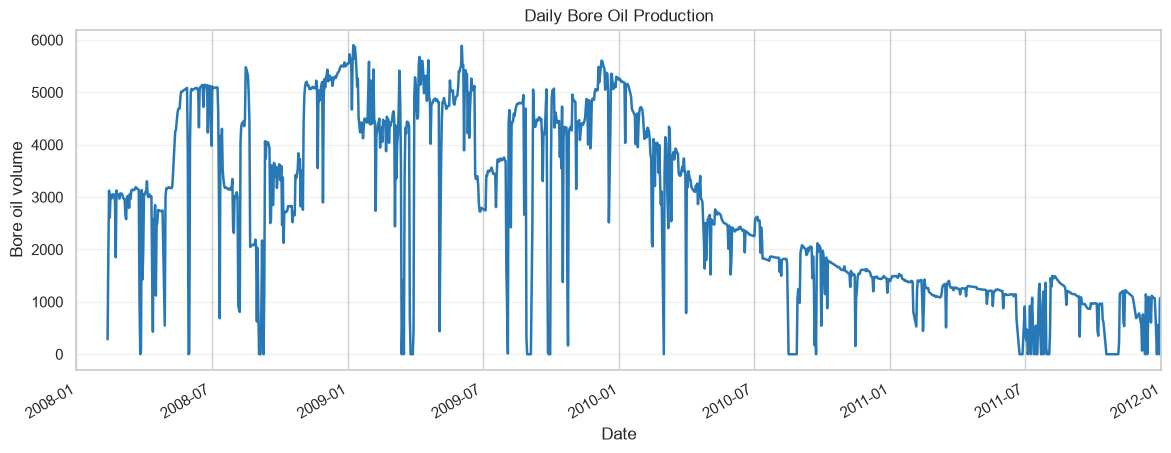

In [23]:
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
ax = train_df["BORE_OIL_VOL"].plot(xlim=["2008-01-01", "2012"], figsize=(14, 5), title="Daily Bore Oil Production", color="#2878B5", linewidth=1.8)
ax.set(xlabel="Date", ylabel="Bore oil volume")
ax.grid(axis="y", alpha=0.25)
plt.savefig(FIGURES_DIR / "01_daily_bore_oil_production.png", dpi=300, bbox_inches="tight")

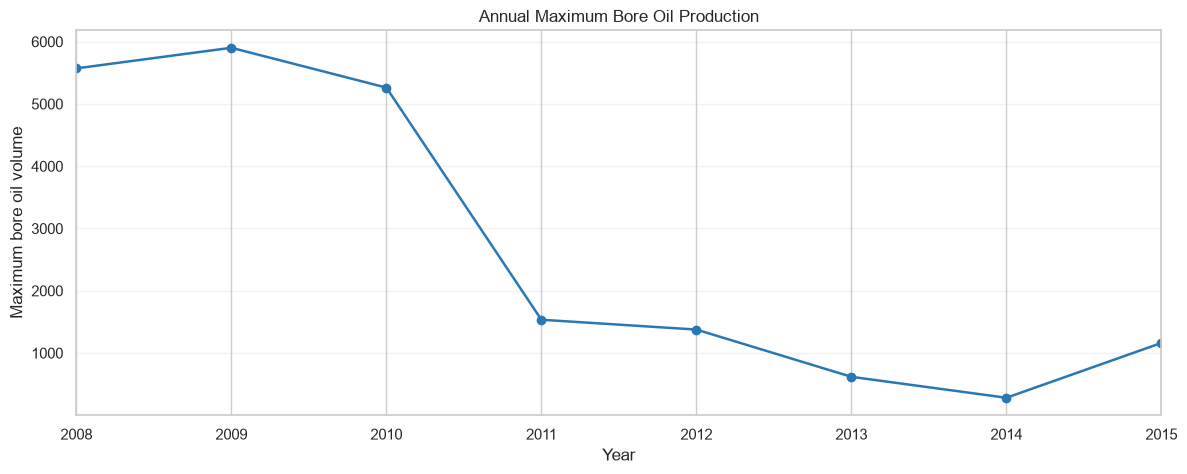

In [24]:
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
ax = train_df["BORE_OIL_VOL"].resample(rule="YE").max().plot(figsize=(14, 5), title="Annual Maximum Bore Oil Production", color="#2878B5", linewidth=1.8, marker="o")
ax.set(xlabel="Year", ylabel="Maximum bore oil volume")
ax.grid(axis="y", alpha=0.25)
plt.savefig(FIGURES_DIR / "02_annual_maximum_bore_oil_production.png", dpi=300, bbox_inches="tight")


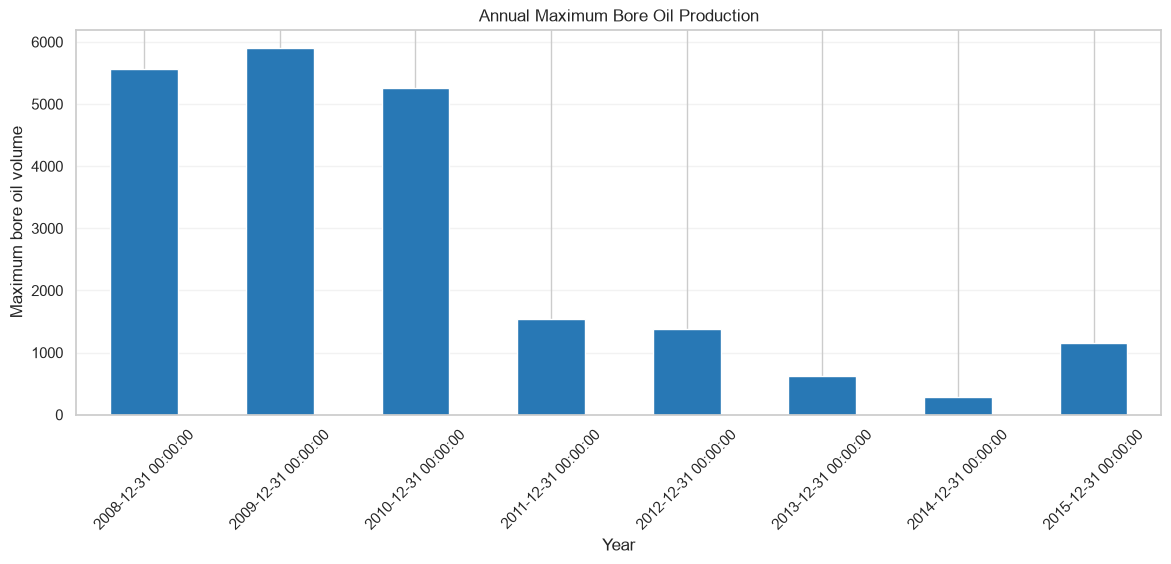

In [25]:
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
ax = train_df["BORE_OIL_VOL"].resample(rule="YE").max().plot(kind="bar", figsize=(14, 5), title="Annual Maximum Bore Oil Production", color="#2878B5", edgecolor="white")
ax.set(xlabel="Year", ylabel="Maximum bore oil volume")
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", alpha=0.25)
plt.savefig(FIGURES_DIR / "03_annual_maximum_bore_oil_production_bar.png", dpi=300, bbox_inches="tight")


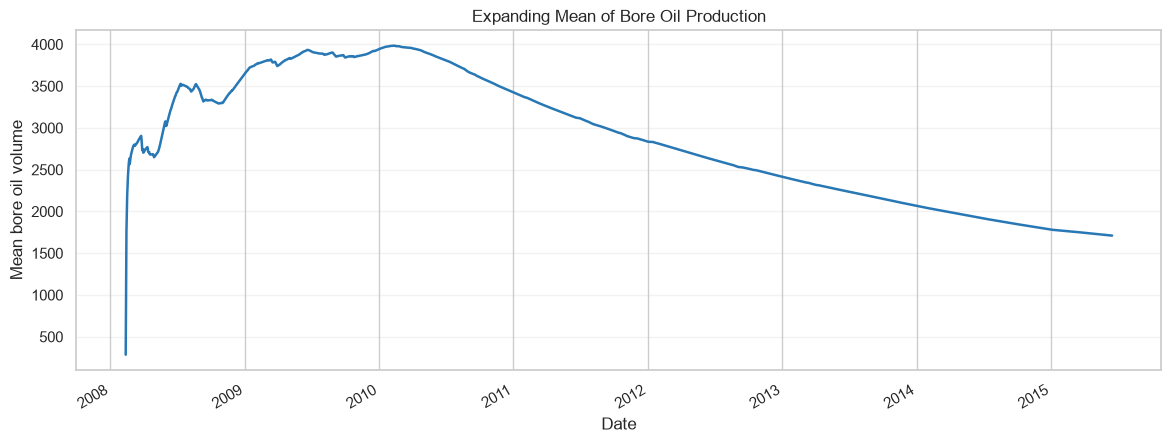

In [26]:
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
ax = train_df["BORE_OIL_VOL"].expanding().mean().plot(xlabel="Date", ylabel="Mean bore oil volume", figsize=(14, 5), title="Expanding Mean of Bore Oil Production", color="#2878B5", linewidth=1.8)
ax.grid(axis="y", alpha=0.25)
plt.savefig(FIGURES_DIR / "04_expanding_mean_bore_oil_production.png", dpi=300, bbox_inches="tight")


## Time-Series Diagnostics

Difference the training target and review stationarity, seasonal decomposition, and autocorrelation to guide ARIMA.

### Stationarity Diagnostics

Difference the training target for diagnostics; retain raw production for forecasting.

In [27]:
train_df['Differenced_BORE_OIL_VOL'] = train_df['BORE_OIL_VOL'].diff()
 
# Drop missing values resulting from differencing
train_df.dropna(inplace=True)

In [28]:
print(train_df[['BORE_OIL_VOL', 'Differenced_BORE_OIL_VOL']].head())

            BORE_OIL_VOL  Differenced_BORE_OIL_VOL
DATEPRD                                           
2008-02-13       1869.70                   1585.05
2008-02-14       3124.09                   1254.39
2008-02-15       2608.28                   -515.81
2008-02-16       3051.80                    443.52
2008-02-17       2982.63                    -69.17


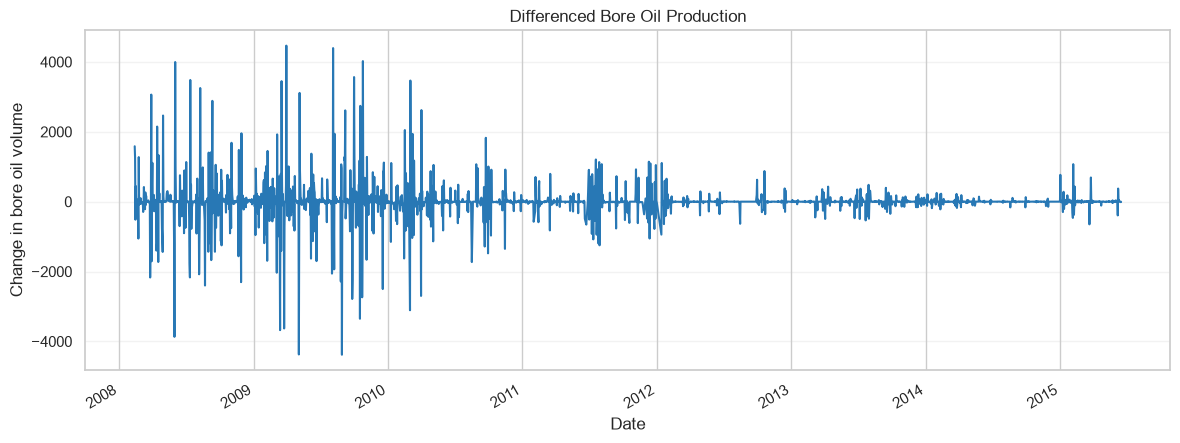

In [29]:
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
ax = train_df["Differenced_BORE_OIL_VOL"].plot(figsize=(14, 5), title="Differenced Bore Oil Production", color="#2878B5", linewidth=1.5)
ax.set(xlabel="Date", ylabel="Change in bore oil volume")
ax.grid(axis="y", alpha=0.25)
plt.savefig(FIGURES_DIR / "05_differenced_bore_oil_production.png", dpi=300, bbox_inches="tight")


In [30]:
diagnostic_result = sm.tsa.stattools.adfuller(train_df['Differenced_BORE_OIL_VOL'])
print('ADF Statistic:', diagnostic_result[0])
print('p-value:', diagnostic_result[1])

if diagnostic_result[1] < 0.05:
    print("Data is stationary")
else:
    print("Data is non-stationary")

ADF Statistic: -17.038380198999533
p-value: 8.23000525237483e-30
Data is stationary


C:\Users\baqee\AppData\Local\Temp\ipykernel_25880\2628700272.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  diagnostic_result = sm.tsa.stattools.adfuller(train_df['Differenced_BORE_OIL_VOL'])


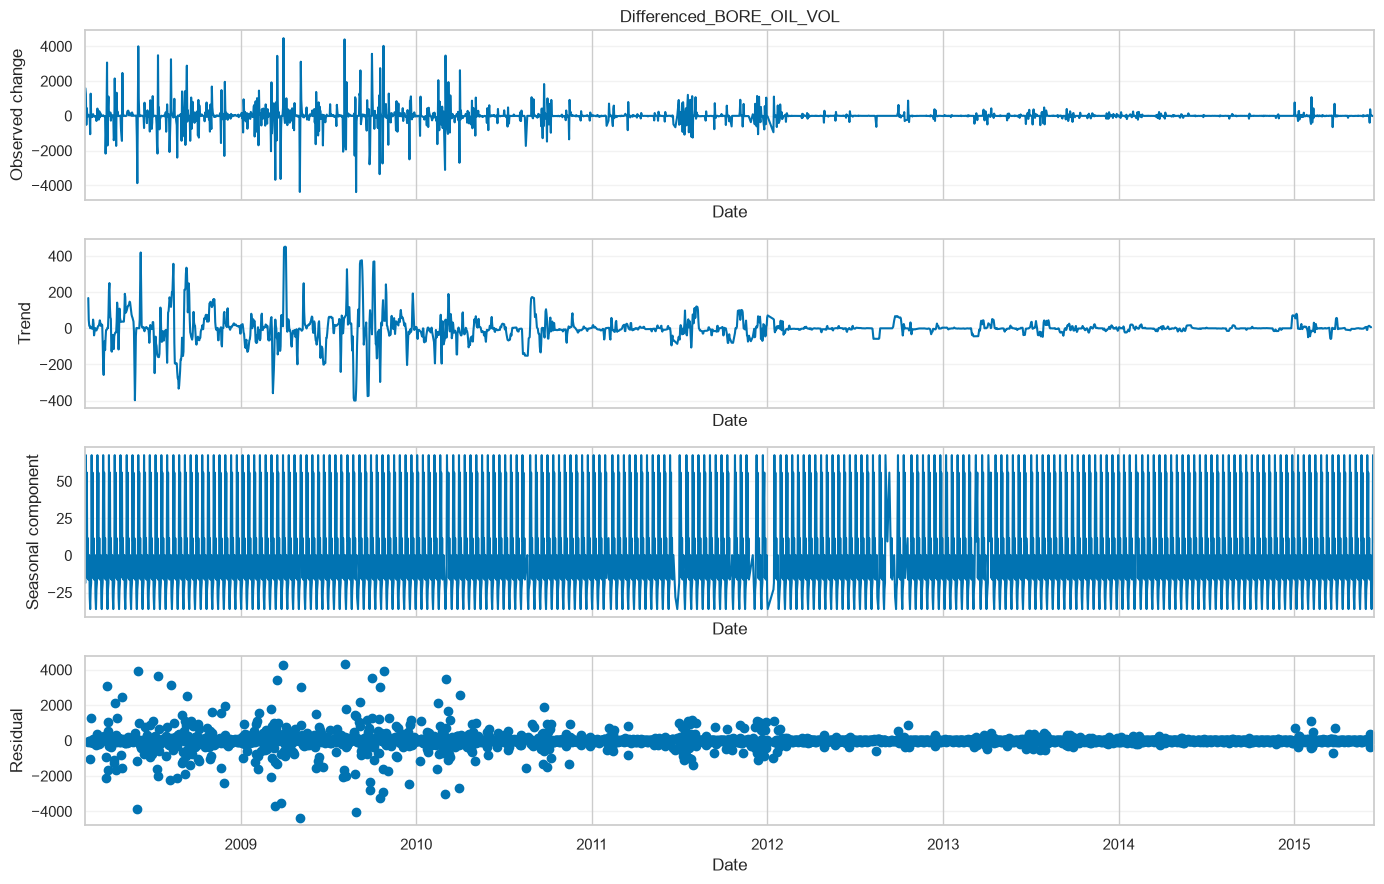

In [31]:
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
from statsmodels.tsa.seasonal import seasonal_decompose
diagnostic_result = seasonal_decompose(train_df["Differenced_BORE_OIL_VOL"], model="additive", period=12)
fig = diagnostic_result.plot()
fig.set_size_inches(14, 9)
for ax, label in zip(fig.axes, ["Observed change", "Trend", "Seasonal component", "Residual"]):
    ax.set_xlabel("Date")
    ax.set_ylabel(label)
    ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.savefig(FIGURES_DIR / "06_seasonal_decomposition.png", dpi=300, bbox_inches="tight")
plt.show()


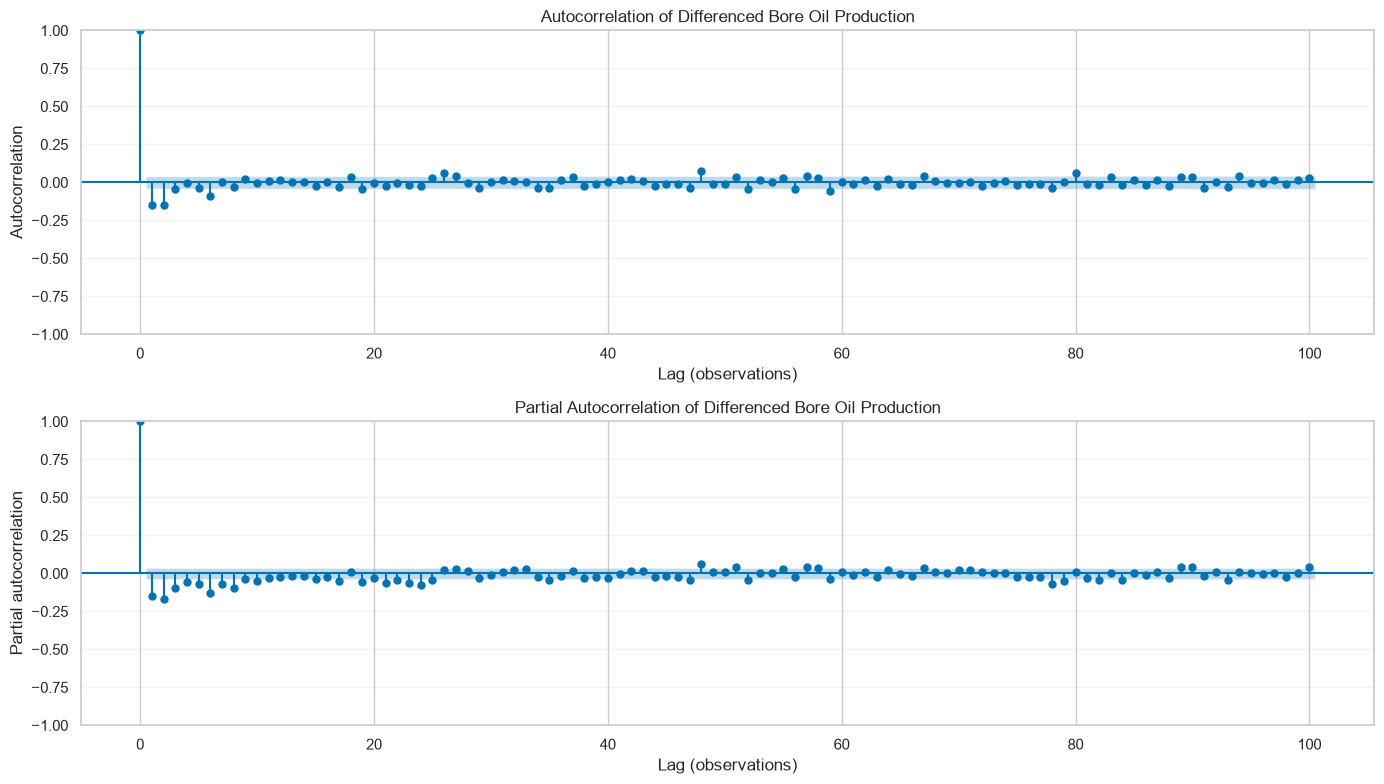

In [32]:
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
differenced_oil_volume = train_df["Differenced_BORE_OIL_VOL"].dropna()
fig, axes = plt.subplots(2, 1, figsize=(14, 8))
plot_acf(differenced_oil_volume, lags=100, ax=axes[0], title="Autocorrelation of Differenced Bore Oil Production")
plot_pacf(differenced_oil_volume, lags=100, ax=axes[1], method="ywadjusted", title="Partial Autocorrelation of Differenced Bore Oil Production")
axes[0].set(xlabel="Lag (observations)", ylabel="Autocorrelation")
axes[1].set(xlabel="Lag (observations)", ylabel="Partial autocorrelation")
for ax in axes:
    ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.savefig(FIGURES_DIR / "07_acf_pacf_differenced_production.png", dpi=300, bbox_inches="tight")
plt.show()


## Forecasting Models

Compare ARIMA, XGBoost, and LSTM.

### ARIMA

Fit ARIMA(3, 1, 2), forecast 30 days, and inspect test predictions and residuals.

In [33]:
training_oil_volume = train_df['BORE_OIL_VOL'].reset_index(drop=True)
model = sm.tsa.ARIMA(training_oil_volume, order=(3, 1, 2))
arima_model_fit = model.fit()

arima_forecast = arima_model_fit.forecast(steps=30)

arima_forecast.index = pd.date_range(
    start=train_df.index[-1] + pd.Timedelta(days=1),
    periods=30,
    freq="D"
)

d:\GitHub\.ML_Environment\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
d:\GitHub\.ML_Environment\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


In [34]:
arima_model_fit.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                               SARIMAX Results                                
==============================================================================
Dep. Variable:           BORE_OIL_VOL   No. Observations:                 2596
Model:                 ARIMA(3, 1, 2)   Log Likelihood              -19590.910
Date:                Sat, 24 Oct 2026   AIC                          39193.820
Time:                        16:15:03   BIC                          39228.988
Sample:                             0   HQIC                         39206.564
                               - 2596                                         
Covariance Type:                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.0854      0.117     -0.727      0.467      -0.316       0.145
ar.L2          0.5070      0.083      6.099      0.000       0.344       0.670
ar.L3          0.0227      0.012      1.896      0.058      -0.001       0.046
ma.L1         -0.1695      0.116     -1.461      0.144      -0.397       0.058
ma.L2         -0.7264      0.108     -6.740      0.000      -0.938      -0.515
sigma2      2.176e+05   1965.766    110.685      0.000    2.14e+05    2.21e+05
===================================================================================
Ljung-Box (L1) (Q):                   0.00   Jarque-Bera (JB):             65873.13
Prob(Q):                              0.96   Prob(JB):                         0.00
Heteroskedasticity (H):               0.02   Skew:                            -1.28
Prob(H) (two-sided):                  0.00   Kurtosis:                        27.55
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

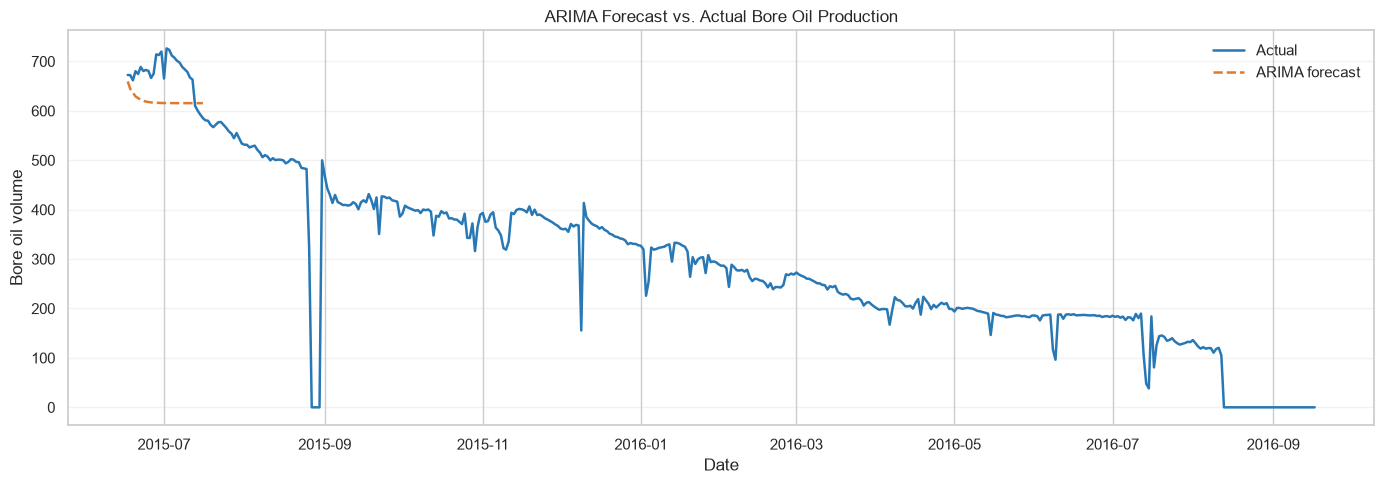

In [35]:
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(test_df.index, test_df["BORE_OIL_VOL"], label="Actual", color="#2878B5", linewidth=1.8)
ax.plot(arima_forecast.index, arima_forecast, label="ARIMA forecast", color="#E07A2D", linewidth=1.8, linestyle="--")
ax.set(title="ARIMA Forecast vs. Actual Bore Oil Production", xlabel="Date", ylabel="Bore oil volume")
ax.grid(axis="y", alpha=0.25)
ax.legend(frameon=False)
fig.tight_layout()
plt.savefig(FIGURES_DIR / "08_arima_forecast_vs_actual.png", dpi=300, bbox_inches="tight")
plt.show()


In [36]:

residuals = pd.Series(test_df["BORE_OIL_VOL"] - arima_forecast, index=test_df.index, name="Residuals")


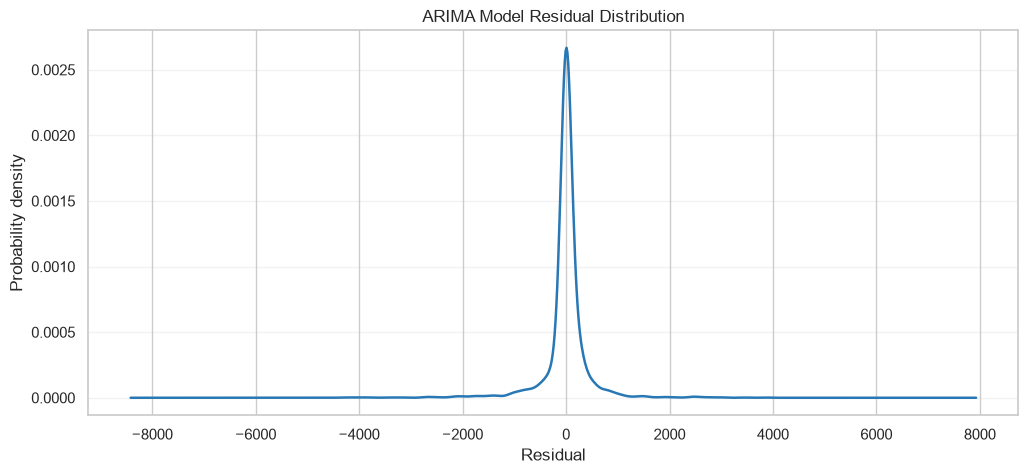

In [37]:
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
ax = arima_model_fit.resid.plot(kind="kde", figsize=(12, 5), title="ARIMA Model Residual Distribution", color="#2878B5", linewidth=1.8)
ax.set(xlabel="Residual", ylabel="Probability density")
ax.grid(axis="y", alpha=0.25)
plt.savefig(FIGURES_DIR / "09_arima_residual_distribution.png", dpi=300, bbox_inches="tight")


### XGBoost with 30-Day Lags

Use 30 prior days as features; validation guides model selection and test is held out.

### Build Lag Features and Holdout Windows

Create `lag_1` through `lag_30` and use chronological train, validation, and test windows.

In [38]:
def lag_features(df, n=30):
    df= df.copy()
    lag_feature_names=[]
    for i in range(1,n+1):
        df[f"lag_{i}"] = df["BORE_OIL_VOL"].shift(i)
        lag_feature_names.append(f"lag_{i}")

    return df, lag_feature_names

In [39]:
train_df, lag_feature_names= lag_features(train_df, n=30)
test_df, _= lag_features(test_df, n=30)
train_df.dropna(inplace=True)

#### Chronological Train and Validation Windows

Training ends 2014-07-15; validation runs 2014-08-16–2015-06-16. The gap is intentional.

In [40]:
x_train = train_df.loc[: "2014-07-15", lag_feature_names]
y_train = train_df.loc[: "2014-07-15", "BORE_OIL_VOL"]

x_val = train_df.loc["2014-08-16":"2015-06-16", lag_feature_names]
y_val = train_df.loc["2014-08-16":"2015-06-16", "BORE_OIL_VOL"]

In [41]:
x_train.loc[:,lag_feature_names].tail(30)

,lag_1,lag_2,lag_3,lag_4,lag_5,lag_6,lag_7,lag_8,lag_9,lag_10,...,lag_21,lag_22,lag_23,lag_24,lag_25,lag_26,lag_27,lag_28,lag_29,lag_30
DATEPRD,,,,,,,,,,,,,,,,,,,,,
2014-06-16,190.81,190.40,193.50,205.41,205.71,205.19,231.66,205.52,205.56,204.19,...,144.14,1.30,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
2014-06-17,192.67,190.81,190.40,193.50,205.41,205.71,205.19,231.66,205.52,205.56,...,164.82,144.14,1.30,0.00,0.00,0.00,0.00,0.00,0.00,0.00
2014-06-18,188.43,192.67,190.81,190.40,193.50,205.41,205.71,205.19,231.66,205.52,...,189.10,164.82,144.14,1.30,0.00,0.00,0.00,0.00,0.00,0.00
2014-06-19,187.27,188.43,192.67,190.81,190.40,193.50,205.41,205.71,205.19,231.66,...,190.12,189.10,164.82,144.14,1.30,0.00,0.00,0.00,0.00,0.00
2014-06-20,186.05,187.27,188.43,192.67,190.81,190.40,193.50,205.41,205.71,205.19,...,191.25,190.12,189.10,164.82,144.14,1.30,0.00,0.00,0.00,0.00
2014-06-21,185.52,186.05,187.27,188.43,192.67,190.81,190.40,193.50,205.41,205.71,...,194.94,191.25,190.12,189.10,164.82,144.14,1.30,0.00,0.00,0.00
2014-06-22,184.04,185.52,186.05,187.27,188.43,192.67,190.81,190.40,193.50,205.41,...,196.08,194.94,191.25,190.12,189.10,164.82,144.14,1.30,0.00,0.00
2014-06-23,182.39,184.04,185.52,186.05,187.27,188.43,192.67,190.81,190.40,193.50,...,194.41,196.08,194.94,191.25,190.12,189.10,164.82,144.14,1.30,0.00
2014-06-24,179.37,182.39,184.04,185.52,186.05,187.27,188.43,192.67,190.81,190.40,...,194.94,194.41,196.08,194.94,191.25,190.12,189.10,164.82,144.14,1.30


In [42]:
x_val.loc[:,lag_feature_names].head(30)

,lag_1,lag_2,lag_3,lag_4,lag_5,lag_6,lag_7,lag_8,lag_9,lag_10,...,lag_21,lag_22,lag_23,lag_24,lag_25,lag_26,lag_27,lag_28,lag_29,lag_30
DATEPRD,,,,,,,,,,,,,,,,,,,,,
2014-08-16,175.96,175.42,174.51,175.23,175.91,170.25,170.15,173.47,174.56,180.22,...,186.07,189.06,190.51,188.17,189.90,191.45,191.61,185.94,186.27,187.62
2014-08-17,175.16,175.96,175.42,174.51,175.23,175.91,170.25,170.15,173.47,174.56,...,189.06,186.07,189.06,190.51,188.17,189.90,191.45,191.61,185.94,186.27
2014-08-18,175.23,175.16,175.96,175.42,174.51,175.23,175.91,170.25,170.15,173.47,...,187.63,189.06,186.07,189.06,190.51,188.17,189.90,191.45,191.61,185.94
2014-08-19,174.03,175.23,175.16,175.96,175.42,174.51,175.23,175.91,170.25,170.15,...,186.18,187.63,189.06,186.07,189.06,190.51,188.17,189.90,191.45,191.61
2014-08-20,10.20,174.03,175.23,175.16,175.96,175.42,174.51,175.23,175.91,170.25,...,153.93,186.18,187.63,189.06,186.07,189.06,190.51,188.17,189.90,191.45
2014-08-21,0.00,10.20,174.03,175.23,175.16,175.96,175.42,174.51,175.23,175.91,...,181.66,153.93,186.18,187.63,189.06,186.07,189.06,190.51,188.17,189.90
2014-08-22,0.00,0.00,10.20,174.03,175.23,175.16,175.96,175.42,174.51,175.23,...,183.95,181.66,153.93,186.18,187.63,189.06,186.07,189.06,190.51,188.17
2014-08-23,0.00,0.00,0.00,10.20,174.03,175.23,175.16,175.96,175.42,174.51,...,184.75,183.95,181.66,153.93,186.18,187.63,189.06,186.07,189.06,190.51
2014-08-24,0.00,0.00,0.00,0.00,10.20,174.03,175.23,175.16,175.96,175.42,...,183.88,184.75,183.95,181.66,153.93,186.18,187.63,189.06,186.07,189.06


#### Test Evaluation

Test predictions are rolling one-step-ahead: each can use actual observations available through the prior day.

In [43]:
test_df.dropna(inplace=True)
x_test= test_df[lag_feature_names]
y_test= test_df["BORE_OIL_VOL"]

In [44]:
xgboost_model = XGBRegressor(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.05,
    random_state=SEED,
    n_jobs=1
)

In [45]:
xgboost_model.fit(
    x_train,
    y_train,
    eval_set=[
        (x_train, y_train), 
        (x_val, y_val)
        ],
    verbose=100  
)

[0]	validation_0-rmse:1678.94136	validation_1-rmse:1431.26033
[100]	validation_0-rmse:166.66847	validation_1-rmse:105.49624
[200]	validation_0-rmse:117.89839	validation_1-rmse:101.16371
[300]	validation_0-rmse:80.45515	validation_1-rmse:99.57251
[400]	validation_0-rmse:56.26171	validation_1-rmse:99.98306
[499]	validation_0-rmse:41.50054	validation_1-rmse:101.39226


,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [46]:
xgboost_predictions = xgboost_model.predict(x_test)

In [47]:
rmse = np.sqrt(mean_squared_error(y_test, xgboost_predictions))
r2 = r2_score(y_test, xgboost_predictions)
print(f"Root Mean Squared Error: {rmse}")
print(f"R-squared: {r2}")

Root Mean Squared Error: 52.86875244665832
R-squared: 0.8644603922459501


#### Optional Hyperparameter Search

Optuna tuning is commented out; the active model uses fixed parameters.

In [48]:
def objective(trial):

    params = {
        "n_estimators": trial.suggest_int(
            "n_estimators", 300, 1500
        ),

        "learning_rate": trial.suggest_float(
            "learning_rate", 0.01, 0.1, log=True
        ),

        "max_depth": trial.suggest_int(
            "max_depth", 2, 10
        ),

        "min_child_weight": trial.suggest_int(
            "min_child_weight", 1, 10
        ),

        "subsample": trial.suggest_float(
            "subsample", 0.6, 1.0
        ),

        "colsample_bytree": trial.suggest_float(
            "colsample_bytree", 0.6, 1.0
        ),

        "gamma": trial.suggest_float(
            "gamma", 0, 5
        ),

        "reg_alpha": trial.suggest_float(
            "reg_alpha", 1e-8, 10.0, log=True
        ),

        "reg_lambda": trial.suggest_float(
            "reg_lambda", 1e-8, 10.0, log=True
        ),

        "objective": "reg:squarederror",

        "n_jobs": -1,

        "random_state": 42,

        "early_stopping_rounds": 50
    }

    model = XGBRegressor(**params)

    model.fit(
        x_train,
        y_train,
        eval_set=[(x_val, y_val)],
        verbose=False
    )

    val_pred = model.predict(x_val)

    rmse = np.sqrt(
        mean_squared_error(y_val, val_pred)
    )

    return rmse

In [49]:
sampler = optuna.samplers.TPESampler(seed=SEED)

study = optuna.create_study(
    direction="minimize",
    sampler=sampler
)

[I 2026-10-24 16:15:06,078] A new study created in memory with name: no-name-eb738492-d2a5-4fd1-ad73-d6251915fa0e


In [50]:
sampler = optuna.samplers.TPESampler(seed=SEED)

study = optuna.create_study(
    direction="minimize",
    study_name="xgb_production_forecasting",
    sampler=sampler,
)

study.optimize(
    objective,
    n_trials=100,
)

[I 2026-10-24 16:15:06,084] A new study created in memory with name: xgb_production_forecasting
[I 2026-10-24 16:15:06,578] Trial 0 finished with value: 109.71946614997037 and parameters: {'n_estimators': 749, 'learning_rate': 0.08927180304353628, 'max_depth': 8, 'min_child_weight': 6, 'subsample': 0.6624074561769746, 'colsample_bytree': 0.662397808134481, 'gamma': 0.2904180608409973, 'reg_alpha': 0.6245760287469893, 'reg_lambda': 0.002570603566117598}. Best is trial 0 with value: 109.71946614997037.
[I 2026-10-24 16:15:08,699] Trial 1 finished with value: 104.12471417748431 and parameters: {'n_estimators': 1150, 'learning_rate': 0.010485387725194618, 'max_depth': 10, 'min_child_weight': 9, 'subsample': 0.6849356442713105, 'colsample_bytree': 0.6727299868828402, 'gamma': 0.9170225492671691, 'reg_alpha': 5.472429642032198e-06, 'reg_lambda': 0.00052821153945323}. Best is trial 1 with value: 104.12471417748431.
[I 2026-10-24 16:15:09,640] Trial 2 finished with value: 102.75360954661731 an

In [51]:
best_params = study.best_params.copy()

best_params.update({
    "objective": "reg:squarederror",
    "n_jobs": -1,
    "random_state": 42,
    "early_stopping_rounds": 50
})

final_model = XGBRegressor(**best_params)

final_model.fit(
    x_train,
    y_train,
    eval_set=[(x_val, y_val)],
    verbose=False
)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.9929980444220067
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",50
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [52]:
test_pred = final_model.predict(x_test)

test_rmse = np.sqrt(
    mean_squared_error(y_test, test_pred)
)

test_r2 = r2_score(y_test, test_pred)
print(f"Test RMSE: {test_rmse:.2f}")
print(f"Test R^2: {test_r2:.2f}")

Test RMSE: 50.14
Test R^2: 0.88


In [53]:
print("Best validation RMSE:", study.best_value)
print("Best parameters:")
print(study.best_params)

print("Train shape:", x_train.shape)
print("Validation shape:", x_val.shape)
print("Test shape:", x_test.shape)

Best validation RMSE: 95.95531589440111
Best parameters:
{'n_estimators': 773, 'learning_rate': 0.09233895673738776, 'max_depth': 8, 'min_child_weight': 2, 'subsample': 0.9799173459040131, 'colsample_bytree': 0.9929980444220067, 'gamma': 3.0866676481684614, 'reg_alpha': 3.261262013762716e-08, 'reg_lambda': 0.004660916782744579}
Train shape: (2230, 30)
Validation shape: (305, 30)
Test shape: (429, 30)


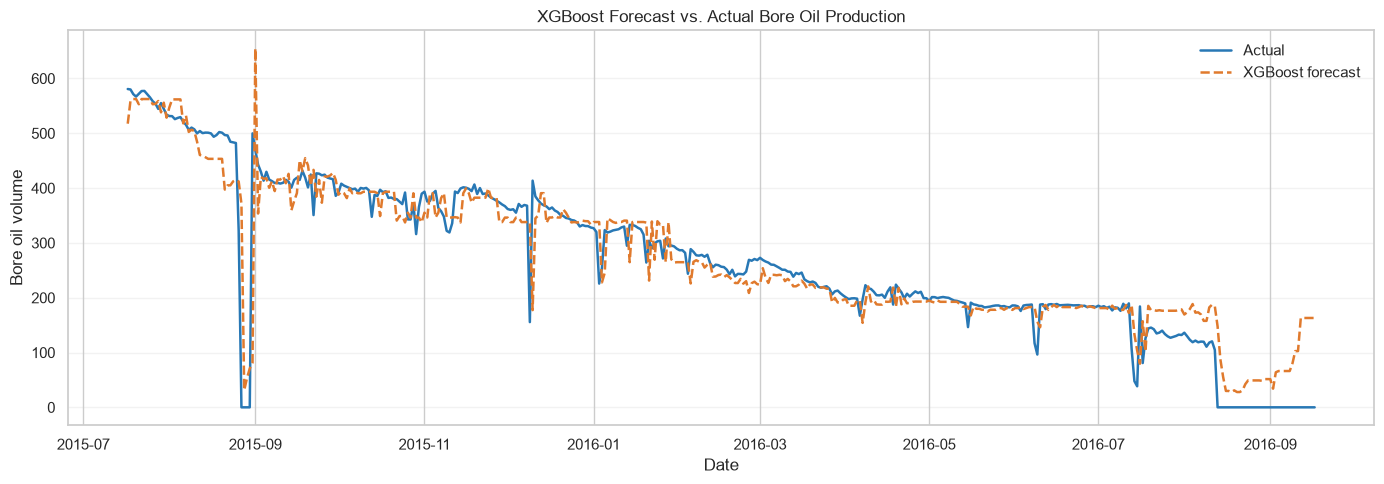

In [54]:
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(test_df.index, test_df["BORE_OIL_VOL"], label="Actual", color="#2878B5", linewidth=1.8)
ax.plot(test_df.index, test_pred, label="XGBoost forecast", color="#E07A2D", linewidth=1.8, linestyle="--")
ax.set(title="XGBoost Forecast vs. Actual Bore Oil Production", xlabel="Date", ylabel="Bore oil volume")
ax.grid(axis="y", alpha=0.25)
ax.legend(frameon=False)
fig.tight_layout()
plt.savefig(FIGURES_DIR / "10_xgboost_forecast_vs_actual", dpi=300, bbox_inches="tight")
plt.show()

In [55]:
model= joblib.dump(final_model, model_DIR/"xgboost_model.pkl")

### LSTM with the Same Lag Windows

Use 30 lags as a sequence. Fit scalers on training data, use validation for early stopping, and score predictions in production units.

### LSTM Training and Evaluation

Scale the lags and target using training statistics, train with validation-based early stopping, and plot test predictions in original units.

In [56]:
from sklearn.preprocessing import StandardScaler

feature_scaler = StandardScaler()
target_scaler = StandardScaler()

x_train_scaled = feature_scaler.fit_transform(x_train)
x_val_scaled = feature_scaler.transform(x_val)
x_test_scaled = feature_scaler.transform(x_test)

y_train_scaled = target_scaler.fit_transform(y_train.to_numpy().reshape(-1, 1))
y_val_scaled = target_scaler.transform(y_val.to_numpy().reshape(-1, 1))

x_train_lstm = x_train_scaled.reshape(x_train_scaled.shape[0], len(lag_feature_names), 1)
x_val_lstm = x_val_scaled.reshape(x_val_scaled.shape[0], len(lag_feature_names), 1)
x_test_lstm = x_test_scaled.reshape(x_test_scaled.shape[0], len(lag_feature_names), 1)


In [57]:
from keras.callbacks import EarlyStopping

lstm_model = Sequential()
lstm_model.add(LSTM(64, input_shape=(len(lag_feature_names), 1)))
lstm_model.add(Dense(1))

lstm_model.compile(optimizer="adam", loss="mean_squared_error")


d:\GitHub\.ML_Environment\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [58]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=30,
    restore_best_weights=True
)

history = lstm_model.fit(
    x_train_lstm,
    y_train_scaled,
    validation_data=(x_val_lstm, y_val_scaled),
    epochs=100,
    batch_size=16,
    shuffle=False,
    callbacks=[early_stopping],
    verbose=10
)


Epoch 1/100
Epoch 2/100
Epoch 3/100
Epoch 4/100
Epoch 5/100
Epoch 6/100
Epoch 7/100
Epoch 8/100
Epoch 9/100
Epoch 10/100
Epoch 11/100
Epoch 12/100
Epoch 13/100
Epoch 14/100
Epoch 15/100
Epoch 16/100
Epoch 17/100
Epoch 18/100
Epoch 19/100
Epoch 20/100
Epoch 21/100
Epoch 22/100
Epoch 23/100
Epoch 24/100
Epoch 25/100
Epoch 26/100
Epoch 27/100
Epoch 28/100
Epoch 29/100
Epoch 30/100
Epoch 31/100
Epoch 32/100
Epoch 33/100
Epoch 34/100
Epoch 35/100
Epoch 36/100
Epoch 37/100
Epoch 38/100
Epoch 39/100
Epoch 40/100
Epoch 41/100
Epoch 42/100
Epoch 43/100
Epoch 44/100
Epoch 45/100
Epoch 46/100
Epoch 47/100
Epoch 48/100
Epoch 49/100
Epoch 50/100
Epoch 51/100
Epoch 52/100
Epoch 53/100
Epoch 54/100
Epoch 55/100
Epoch 56/100
Epoch 57/100
Epoch 58/100
Epoch 59/100
Epoch 60/100
Epoch 61/100
Epoch 62/100
Epoch 63/100
Epoch 64/100
Epoch 65/100
Epoch 66/100
Epoch 67/100
Epoch 68/100
Epoch 69/100
Epoch 70/100
Epoch 71/100
Epoch 72/100
Epoch 73/100
Epoch 74/100
Epoch 75/100
Epoch 76/100
Epoch 77/100
Epoch 78

In [59]:
scaled_lstm_predictions = lstm_model.predict(x_test_lstm, verbose=0)
lstm_predictions = target_scaler.inverse_transform(scaled_lstm_predictions).ravel()

lstm_rmse = np.sqrt(mean_squared_error(y_test, lstm_predictions))
lstm_r2 = r2_score(y_test, lstm_predictions)

print(f"Root Mean Squared Error: {lstm_rmse}")
print(f"R-squared: {lstm_r2}")

Root Mean Squared Error: 53.70481214209711
R-squared: 0.860139684622166


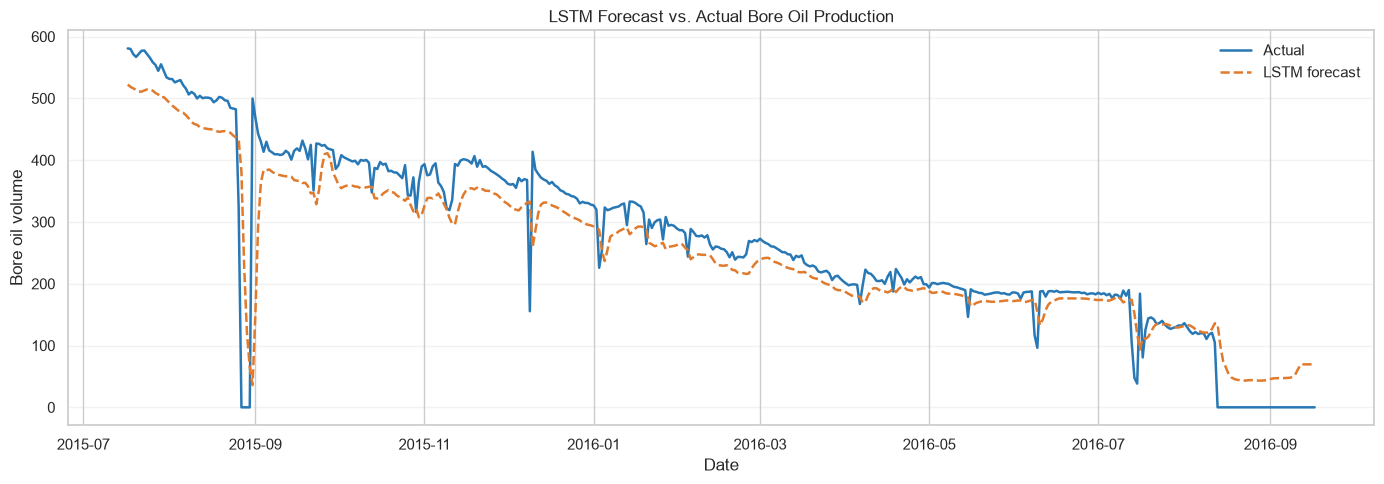

In [60]:
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(y_test.index, y_test, label="Actual", color="#2878B5", linewidth=1.8)
ax.plot(y_test.index, lstm_predictions, label="LSTM forecast", color="#E07A2D", linewidth=1.8, linestyle="--")
ax.set(title="LSTM Forecast vs. Actual Bore Oil Production", xlabel="Date", ylabel="Bore oil volume")
ax.grid(axis="y", alpha=0.25)
ax.legend(frameon=False)
fig.tight_layout()
plt.savefig(FIGURES_DIR / "11_lstm_forecast_vs_actual.png", dpi=300, bbox_inches="tight")
plt.show()


In [61]:
model= joblib.dump(lstm_model, model_DIR/"lstm_model.pkl")